# Credit Risk: clustering analysis (unsupervised learning)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cristhian731/Credit-Risk/blob/main/notebooks/credit_risk_clustering.ipynb)

The credit risk models are **supervised**: they learn from the label "defaulted or repaid". Here we ignore the label to build the groups and use it only afterwards, to check whether the groups differ in default rate. The notebook answers four questions:

1. **Which segments of applicants appear?** K-Means, DBSCAN and Agglomerative Clustering (Ward) on the same standardized features.
2. **Which technique gives the best-defined groups?** Silhouette, Davies-Bouldin and Calinski-Harabasz, and the size of every group.
3. **Do the groups separate the risk of default?** Profile of each cluster (means of the variables and its **real default rate**).
4. **How can the system use the segments?** A documented proposal to support the analyst, without changing the model in production.

Rules that keep the results comparable with the web app:

- The code of the app is reused (`ml/dataset.py`, `ml/pipelines.py`), so the data, the split and the preprocessing are the same ones used to train the models.
- **Only the train split is used.** The test split is deleted right after the split.
- The label is **never** an input of the clustering.
- DBSCAN and Agglomerative Clustering need a distance matrix, so they run on a **stratified sample** of the train split (the same rows for both). K-Means runs on the whole train split.
- Every random step uses the seed 42. The model in production is **not** changed by this notebook.

## 1. Setup

In **Google Colab** the next cell clones the repository and installs `requirements-notebook.txt` (the same package versions as the app, plus matplotlib and seaborn). If Colab asks you to restart the runtime after the installation, restart it and run the notebook again from the top.

Locally, run the notebook from the repository root with the project virtual environment (Python 3.12 or newer).

In [1]:
import os
import subprocess
import sys
import warnings

REPO_URL = "https://github.com/Cristhian731/Credit-Risk.git"
BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not os.path.exists("Credit-Risk"):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL], check=True)
    os.chdir("Credit-Risk")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-notebook.txt"], check=True)
else:
    # Locally: move up to the repository root (the folder that contains ml/).
    while not os.path.isdir("ml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

assert sys.version_info >= (3, 12), "requirements-notebook.txt needs Python 3.12 or newer"
warnings.filterwarnings("ignore", category=FutureWarning)
print("Setup done. Running in Colab:", IN_COLAB)

Setup done. Running in Colab: False


In [2]:
import json

import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")  # figures are saved to files and displayed from them
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.base import clone
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, roc_auc_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

from ml import dataset
from ml.features import ARTIFACTS_DIR, DEFAULT_FEATURE_SET, FEATURE_SETS, MANIFEST_FILENAME, METRICS_FILENAME
from ml.pipelines import RANDOM_STATE, build_pipeline
from ml.schemas import load_json, validate_clustering_report

sns.set_theme(style="whitegrid")
FIG_DIR = os.path.join("static", "img", "methodology")
os.makedirs(FIG_DIR, exist_ok=True)
FIGURES = []


def show(fig, name):
    """Save a figure under static/img/methodology/ (no tool metadata) and display the saved file."""
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=110, bbox_inches="tight", metadata={"Software": None})
    plt.close(fig)
    display(Image(filename=path))
    FIGURES.append(f"methodology/{name}")

## 2. Data

The dataset is the **Loan Default Prediction Dataset** (255,347 rows, 18 columns). It is not stored in the repository.

- **Kaggle:** search for "Loan Default Prediction Dataset" on kaggle.com, download `Loan_default.csv` and keep the file as it is (the app checks its SHA-256; see `ml/data/README.md`).
- **Colab:** if the file is not found, the next cell opens an upload dialog; choose `Loan_default.csv`.
- **Locally:** put the file in `ml/data/raw/`.

`dataset.load` checks the columns and the target, and warns if the SHA-256 differs from the expected one. Then the data is cleaned and split 80/20 (stratified, seed 42) exactly as in `python -m ml.train`. **The test split is deleted immediately.**

In [3]:
DATA_PATH = dataset.DEFAULT_DATA_PATH
if not os.path.exists(DATA_PATH):
    if IN_COLAB:
        from google.colab import files

        os.makedirs(os.path.dirname(DATA_PATH), exist_ok=True)
        uploaded = files.upload()  # choose Loan_default.csv
        os.replace(next(iter(uploaded)), DATA_PATH)
    else:
        raise FileNotFoundError("Put Loan_default.csv in ml/data/raw/ (see ml/data/README.md).")

raw = dataset.load(DATA_PATH)
cleaned = dataset.clean(raw)
X_train, X_test, y_train, y_test = dataset.split(cleaned)
del X_test, y_test  # the test split is never used in this notebook

print("Rows:", len(raw), "| train rows:", len(X_train))
print("SHA-256 matches the expected file:", raw.attrs["sha256"] == dataset.EXPECTED_SHA256)
print(f"Default rate in train: {y_train.mean():.2%}")

Rows: 255347 | train rows: 204277
SHA-256 matches the expected file: True
Default rate in train: 11.61%


## 3. Preprocessing and standardization

Clustering is driven by distances, so the scale of the variables matters: `Income` and `LoanAmount` are in the tens of thousands and would dominate `Age` or `DTIRatio`. The cell below takes the **preprocessing of the pipeline of the champion** (median imputation, scaling of the numeric columns and one-hot encoding of `EmploymentType`, which gives 12 columns), fits it on the train split and then **standardizes** every column (mean 0, variance 1). All techniques use this matrix.

It also checks how correlated the features are: if they are almost independent, there is little shape for a clustering algorithm to find.

In [4]:
manifest = load_json(os.path.join(ARTIFACTS_DIR, MANIFEST_FILENAME))
champion = manifest["champion"]
champion_metrics = load_json(os.path.join(ARTIFACTS_DIR, champion, METRICS_FILENAME))
model_cv_auc = float(champion_metrics["cv"]["roc_auc"][0])

FEATURES = FEATURE_SETS[DEFAULT_FEATURE_SET]
NUMERIC = [c for c in FEATURES["columns"] if c not in FEATURES["categorical"]]
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

preprocessor = clone(build_pipeline(champion, scale_pos_weight=scale_pos_weight).named_steps["preprocessing"]).fit(X_train)
Z = preprocessor.transform(X_train)
Z = Z.toarray() if hasattr(Z, "toarray") else np.asarray(Z)
feature_names = [name.split("__", 1)[-1] for name in preprocessor.get_feature_names_out()]
Zs = StandardScaler().fit_transform(Z)
base_rate = float(y_train.mean())

corr = X_train[NUMERIC].corr()
max_feature_corr = float(corr.where(~np.eye(len(NUMERIC), dtype=bool)).abs().max().max())

print(f"{Zs.shape[0]} rows x {Zs.shape[1]} standardized columns: {feature_names}")
print(f"Default rate in train (not used by the clustering): {base_rate:.2%}")
print(f"Largest absolute correlation between two numeric features: {max_feature_corr:.3f}")

204277 rows x 12 standardized columns: ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'LoanTerm', 'DTIRatio', 'EmploymentType_Full-time', 'EmploymentType_Part-time', 'EmploymentType_Self-employed', 'EmploymentType_Unemployed']
Default rate in train (not used by the clustering): 11.61%
Largest absolute correlation between two numeric features: 0.004


## 4. K-Means

K-Means splits the applicants in *k* groups around *k* centres. *k* is chosen with two criteria:

- **Elbow method:** the inertia (sum of squared distances to the centre) always falls when *k* grows; the "elbow" is where the fall slows down.
- **Silhouette:** how much closer a point is to its own cluster than to the nearest other one (from -1 to 1; higher is better). It is computed on a random sample of 10,000 rows, because it needs all the pairwise distances.

The notebook picks the *k* with the highest silhouette and shows the elbow next to it, so the choice can be checked by eye. K-Means runs on the whole train split.

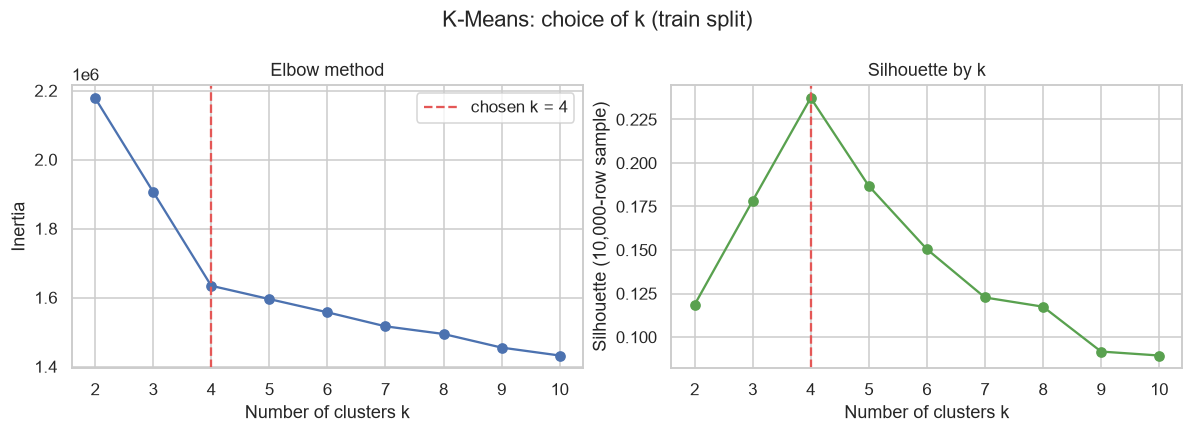

 k      inertia  silhouette
 2 2178645.7963      0.1185
 3 1906467.2442      0.1783
 4 1634200.8305      0.2374
 5 1595564.7811      0.1868
 6 1557260.4673      0.1505
 7 1516597.6481      0.1227
 8 1494391.4215      0.1174
 9 1454941.0786      0.0917
10 1431960.7273      0.0894
Chosen k (highest silhouette): 4


In [5]:
SILHOUETTE_ROWS = 10000
K_RANGE = list(range(2, 11))
k_scores = []
for k in K_RANGE:
    model = KMeans(n_clusters=k, n_init=3, random_state=RANDOM_STATE).fit(Zs)
    sil = silhouette_score(Zs, model.labels_, sample_size=SILHOUETTE_ROWS, random_state=RANDOM_STATE)
    k_scores.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(sil)})

best_k = max(k_scores, key=lambda item: item["silhouette"])["k"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(K_RANGE, [s["inertia"] for s in k_scores], marker="o")
axes[0].axvline(best_k, color="#e45756", linestyle="--", label=f"chosen k = {best_k}")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow method")
axes[0].legend()
axes[1].plot(K_RANGE, [s["silhouette"] for s in k_scores], marker="o", color="#59a14f")
axes[1].axvline(best_k, color="#e45756", linestyle="--")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette (10,000-row sample)")
axes[1].set_title("Silhouette by k")
fig.suptitle("K-Means: choice of k (train split)")
fig.tight_layout()
show(fig, "clustering_kmeans_selection.png")

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Zs)
labels_kmeans_all = kmeans.labels_
print(pd.DataFrame(k_scores).round(4).to_string(index=False))
print(f"Chosen k (highest silhouette): {best_k}")

## 5. DBSCAN

DBSCAN finds dense regions and marks the points that belong to none of them as **noise** (label -1). It needs two parameters:

- `min_samples`: points needed to form a dense region. A common rule is twice the number of dimensions, here 2 x 12 = 24.
- `eps`: the neighbourhood radius. It is read from the **k-distance plot**: for every point, the distance to its 24th nearest neighbour, sorted. The radius is the "knee" where the curve starts to rise sharply (the point farthest from the straight line that joins the ends of the curve).

DBSCAN and Agglomerative Clustering run on the same **stratified sample** (the default rate is kept) of 5,000 rows.

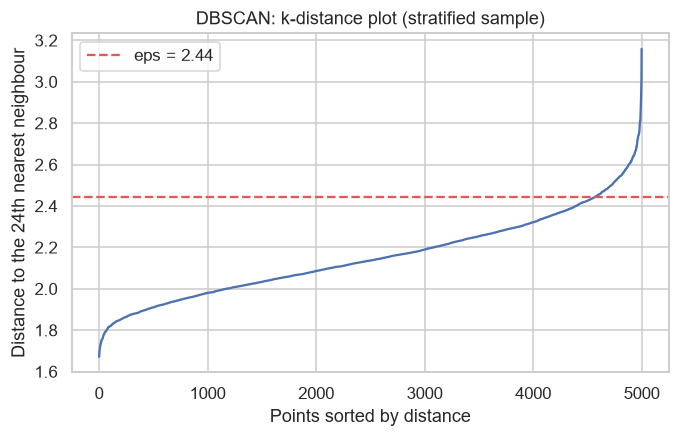

eps = 2.441 | min_samples = 24 | clusters found: 4 | noise: 0.0%
0    1230
1    1230
2    1247
3    1293


In [6]:
SAMPLE_ROWS = 5000
MIN_SAMPLES = 2 * Zs.shape[1]
sample_idx, _ = train_test_split(np.arange(len(Zs)), train_size=SAMPLE_ROWS, stratify=y_train, random_state=RANDOM_STATE)
sample_idx = np.sort(sample_idx)
Zs_s = Zs[sample_idx]
X_s = X_train.iloc[sample_idx]
y_s = y_train.iloc[sample_idx]

distances, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Zs_s).kneighbors(Zs_s)
kdist = np.sort(distances[:, -1])
# Knee: the point of the curve farthest from the line between its first and last point.
x = np.arange(len(kdist))
line = kdist[0] + (kdist[-1] - kdist[0]) * x / (len(kdist) - 1)
knee = int(np.argmax(line - kdist))
eps = float(kdist[knee])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, kdist)
ax.axhline(eps, color="#e45756", linestyle="--", label=f"eps = {eps:.2f}")
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel(f"Distance to the {MIN_SAMPLES}th nearest neighbour")
ax.set_title("DBSCAN: k-distance plot (stratified sample)")
ax.legend()
show(fig, "clustering_dbscan_kdistance.png")

dbscan = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(Zs_s)
labels_dbscan = dbscan.labels_
n_dbscan = int(len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0))
noise_share = float((labels_dbscan == -1).mean())
print(f"eps = {eps:.3f} | min_samples = {MIN_SAMPLES} | clusters found: {n_dbscan} | noise: {noise_share:.1%}")
print(pd.Series(labels_dbscan).value_counts().sort_index().to_string())

## 6. Agglomerative Clustering (Ward)

Agglomerative Clustering starts with every point alone and repeatedly merges the two closest groups. With the **Ward** criterion it merges the pair that increases the within-cluster variance the least, which gives compact groups like K-Means. The **dendrogram** shows the order and the height of the merges: a long vertical line means that two groups that were far apart were forced to merge. It is drawn truncated to the last 30 merges.

The number of clusters is the one chosen for K-Means, so the two techniques can be compared group by group.

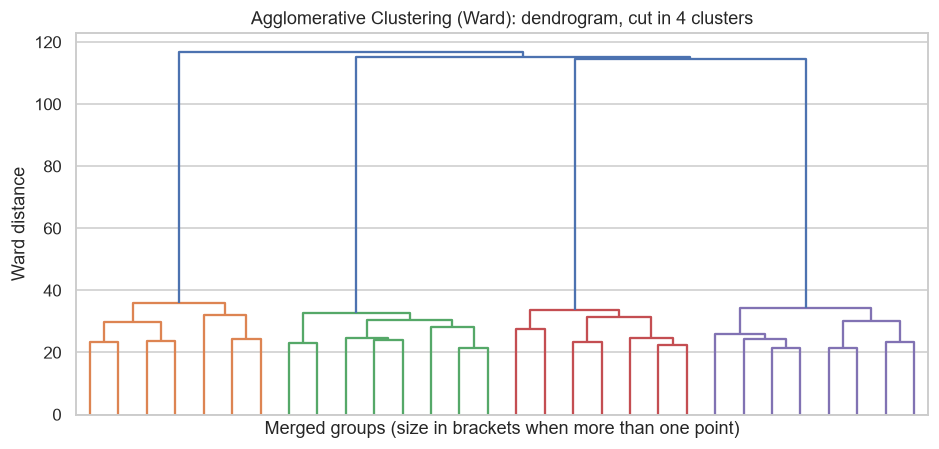

0    1293
1    1230
2    1247
3    1230


In [7]:
link = linkage(Zs_s, method="ward")
fig, ax = plt.subplots(figsize=(10, 4.5))
dendrogram(link, truncate_mode="lastp", p=30, ax=ax, no_labels=True, color_threshold=link[-(best_k - 1), 2])
ax.set_ylabel("Ward distance")
ax.set_xlabel("Merged groups (size in brackets when more than one point)")
ax.set_title(f"Agglomerative Clustering (Ward): dendrogram, cut in {best_k} clusters")
show(fig, "clustering_dendrogram.png")

agglo = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit(Zs_s)
labels_agglo = agglo.labels_
print(pd.Series(labels_agglo).value_counts().sort_index().to_string())

## 7. Comparison of the techniques

Three internal metrics, all computed on the **same 5,000-row sample**, with the label never used:

- **Silhouette** (-1 to 1, higher is better): separation between groups.
- **Davies-Bouldin** (0 upwards, **lower** is better): average similarity of each cluster with its most similar one.
- **Calinski-Harabasz** (higher is better): ratio of between-cluster to within-cluster dispersion.

DBSCAN is evaluated without the noise points, and only if it found at least two clusters.

In [8]:
labels_kmeans_s = kmeans.predict(Zs_s)
techniques = {
    "kmeans": {"label": "K-Means", "labels": labels_kmeans_s},
    "dbscan": {"label": "DBSCAN", "labels": labels_dbscan},
    "agglomerative": {"label": "Agglomerative (Ward)", "labels": labels_agglo},
}


def internal_metrics(points, labels):
    keep = labels != -1
    points, labels = points[keep], labels[keep]
    n_clusters = int(len(set(labels)))
    result = {"rows_evaluated": int(keep.sum()), "n_clusters": n_clusters,
              "silhouette": None, "davies_bouldin": None, "calinski_harabasz": None}
    if n_clusters >= 2:
        result["silhouette"] = round(float(silhouette_score(points, labels)), 4)
        result["davies_bouldin"] = round(float(davies_bouldin_score(points, labels)), 4)
        result["calinski_harabasz"] = round(float(calinski_harabasz_score(points, labels)), 1)
    return result


comparison = {key: internal_metrics(Zs_s, item["labels"]) for key, item in techniques.items()}
table = pd.DataFrame(comparison).T
table.index = [techniques[k]["label"] for k in table.index]
print(table.to_string())

                      rows_evaluated  n_clusters  silhouette  davies_bouldin  calinski_harabasz
K-Means                       5000.0         4.0      0.2368           1.705              839.6
DBSCAN                        5000.0         4.0      0.2368           1.705              839.6
Agglomerative (Ward)          5000.0         4.0      0.2368           1.705              839.6


In [9]:
def profile(frame, target, labels):
    rows = []
    for cluster in sorted(set(labels)):
        mask = labels == cluster
        part = frame[mask]
        means = {name: round(float(part[name].mean()), 2) for name in NUMERIC}
        rows.append({
            "cluster": int(cluster),
            "size": int(mask.sum()),
            "share": round(float(mask.mean()), 4),
            "default_rate": round(float(target[mask].mean()), 4),
            "means": means,
            "main_employment_type": str(part["EmploymentType"].mode().iloc[0]),
        })
    return rows


def separation(rows, target, labels):
    rate = {row["cluster"]: row["default_rate"] for row in rows}
    score = np.array([rate[c] for c in labels])
    rates = [row["default_rate"] for row in rows]
    return {"default_rate_min": round(min(rates), 4), "default_rate_max": round(max(rates), 4),
            "spread": round(max(rates) - min(rates), 4),
            "cluster_roc_auc": round(float(roc_auc_score(target, score)), 4)}

### 7.1 Are the clusters just the employment type?

The three techniques gave suspiciously similar results. The **adjusted Rand index** (ARI) compares a clustering with the categories of `EmploymentType`: 1 means that the clusters are exactly those categories, and 0 means no relation. The standardized one-hot columns of `EmploymentType` are far apart from each other, so a distance-based algorithm may simply find them.

In [10]:
from sklearn.metrics import adjusted_rand_score

employment_all = X_train["EmploymentType"].to_numpy()
employment_s = X_s["EmploymentType"].to_numpy()
employment_alignment = {
    "kmeans": round(float(adjusted_rand_score(employment_all, labels_kmeans_all)), 4),
    "dbscan": round(float(adjusted_rand_score(employment_s, labels_dbscan)), 4),
    "agglomerative": round(float(adjusted_rand_score(employment_s, labels_agglo)), 4),
}
print("Adjusted Rand index with EmploymentType:", employment_alignment)

Adjusted Rand index with EmploymentType: {'kmeans': 1.0, 'dbscan': 1.0, 'agglomerative': 1.0}


### 7.2 Clustering with the numeric variables only

If the clusters come from the categorical column, the numeric variables (age, income, loan amount, credit score, months employed, credit lines, term and debt-to-income ratio) should show no groups at all. The cell repeats K-Means with the 8 standardized numeric columns, with the same criteria (elbow and silhouette, k from 2 to 10).

 k   inertia  silhouette
 2 1480848.0      0.0920
 3 1382628.6      0.0827
 4 1310685.7      0.0841
 5 1254481.8      0.0836
 6 1208706.6      0.0827
 7 1166604.3      0.0835
 8 1127440.9      0.0879
 9 1094495.4      0.0882
10 1069350.1      0.0868
{'default_rate_min': 0.1102, 'default_rate_max': 0.122, 'spread': 0.0118, 'cluster_roc_auc': 0.5144} ARI with EmploymentType: -0.0


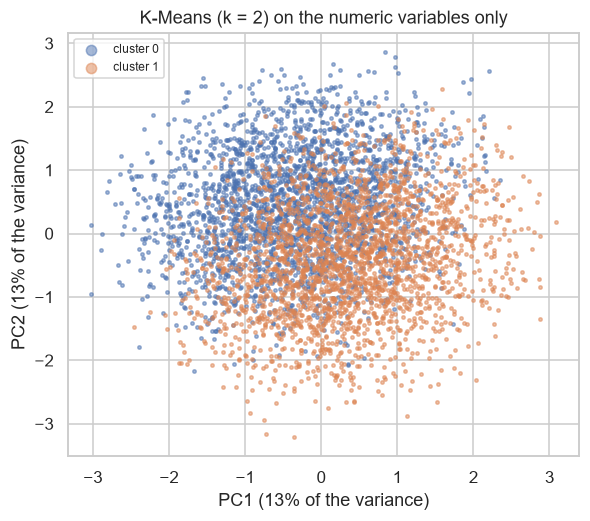

In [11]:
numeric_columns = [i for i, name in enumerate(feature_names) if not name.startswith("EmploymentType_")]
Zn = Zs[:, numeric_columns]
numeric_scores = []
for k in K_RANGE:
    model = KMeans(n_clusters=k, n_init=3, random_state=RANDOM_STATE).fit(Zn)
    sil = silhouette_score(Zn, model.labels_, sample_size=SILHOUETTE_ROWS, random_state=RANDOM_STATE)
    numeric_scores.append({"k": k, "inertia": round(float(model.inertia_), 1), "silhouette": round(float(sil), 4)})
numeric_best_k = max(numeric_scores, key=lambda item: item["silhouette"])["k"]
numeric_labels = KMeans(n_clusters=numeric_best_k, n_init=10, random_state=RANDOM_STATE).fit(Zn).labels_
numeric_rows = profile(X_train, y_train.to_numpy(), numeric_labels)
numeric_only = {
    "columns": [feature_names[i] for i in numeric_columns],
    "k_candidates": numeric_scores,
    "chosen_k": int(numeric_best_k),
    "best_silhouette": max(s["silhouette"] for s in numeric_scores),
    "risk_separation": separation(numeric_rows, y_train.to_numpy(), numeric_labels),
    "employment_alignment": round(float(adjusted_rand_score(employment_all, numeric_labels)), 4),
}
print(pd.DataFrame(numeric_scores).to_string(index=False))
print(numeric_only["risk_separation"], "ARI with EmploymentType:", numeric_only["employment_alignment"])

pca_n = PCA(n_components=2, random_state=RANDOM_STATE).fit(Zn)
Pn = pca_n.transform(Zn[sample_idx])
fig, ax = plt.subplots(figsize=(6, 5))
for cluster in sorted(set(numeric_labels)):
    mask = numeric_labels[sample_idx] == cluster
    ax.scatter(Pn[mask, 0], Pn[mask, 1], s=5, alpha=0.5, label=f"cluster {cluster}")
ax.set_xlabel(f"PC1 ({pca_n.explained_variance_ratio_[0]:.0%} of the variance)")
ax.set_ylabel(f"PC2 ({pca_n.explained_variance_ratio_[1]:.0%} of the variance)")
ax.set_title(f"K-Means (k = {numeric_best_k}) on the numeric variables only")
ax.legend(markerscale=3, fontsize=8)
show(fig, "clustering_pca_numeric.png")

## 8. Profile of each cluster and default rate

For every cluster the cell computes its size, the **mean of every original variable** (before standardizing, so the units are the real ones) and the **real default rate**, using the label that the clustering never saw. K-Means is profiled on the whole train split; DBSCAN and Agglomerative Clustering on the sample, so their rates have more sampling noise.

To measure whether the groups separate the risk, every applicant receives the default rate of his or her cluster as a score, and its **ROC AUC** is calculated in the same data. It can be compared with the cross-validated ROC AUC of the champion model: a segmentation that does not know the label cannot be expected to reach it.


=== K-Means ===
 cluster  size  share  default_rate main_employment_type   Age   Income  LoanAmount  CreditScore  MonthsEmployed  NumCreditLines  LoanTerm  DTIRatio
       0 50932 0.2493        0.0946            Full-time 43.55 82776.85   127559.17       573.37           59.45             2.5     35.94       0.5
       1 51324 0.2512        0.1191            Part-time 43.39 82395.13   127270.88       574.17           59.69             2.5     36.02       0.5
       2 50997 0.2496        0.1355           Unemployed 43.54 82432.27   127815.05       574.83           59.56             2.5     36.03       0.5
       3 51024 0.2498        0.1153        Self-employed 43.56 82519.32   127452.39       575.14           59.61             2.5     35.97       0.5
{'default_rate_min': 0.0946, 'default_rate_max': 0.1355, 'spread': 0.0409, 'cluster_roc_auc': 0.5385}

=== DBSCAN ===
 cluster  size  share  default_rate main_employment_type   Age   Income  LoanAmount  CreditScore  MonthsEmployed  NumCre

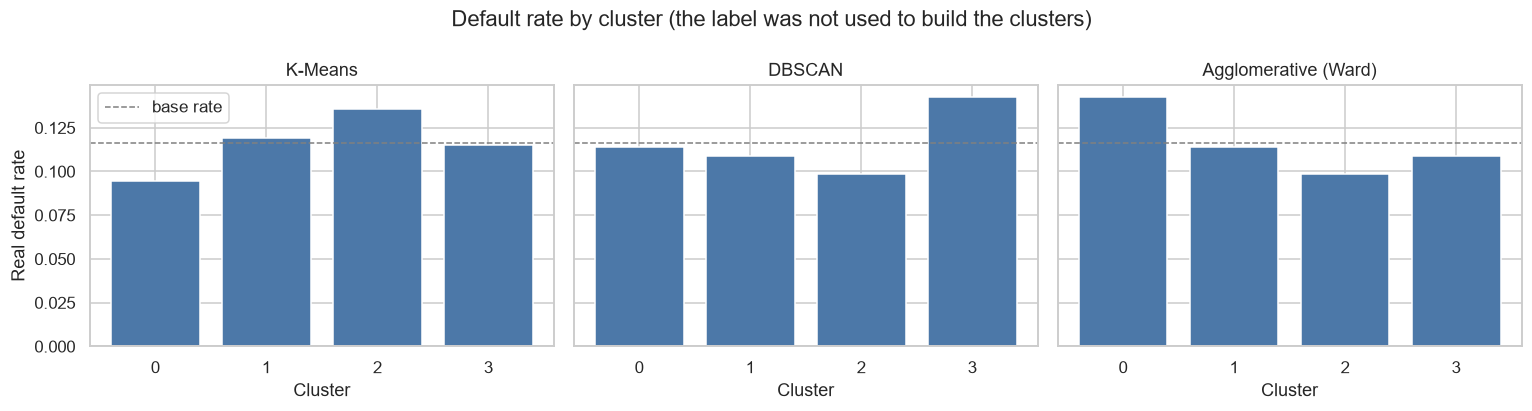

In [12]:
frames = {
    "kmeans": (X_train, y_train.to_numpy(), labels_kmeans_all),
    "dbscan": (X_s, y_s.to_numpy(), labels_dbscan),
    "agglomerative": (X_s, y_s.to_numpy(), labels_agglo),
}
clusters, risk_separation = {}, {}
for key, (frame, target, labels) in frames.items():
    clusters[key] = profile(frame, target, labels)
    risk_separation[key] = separation(clusters[key], target, labels)
    print(f"\n=== {techniques[key]['label']} ===")
    shown = pd.DataFrame([{**{k: v for k, v in r.items() if k != "means"}, **r["means"]} for r in clusters[key]])
    print(shown.to_string(index=False))
    print(risk_separation[key])
print(f"\nBase default rate: {base_rate:.4f} | cross-validated ROC AUC of the champion model: {model_cv_auc:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (key, rows) in zip(axes, clusters.items()):
    names = [("noise" if r["cluster"] == -1 else str(r["cluster"])) for r in rows]
    ax.bar(names, [r["default_rate"] for r in rows], color="#4c78a8")
    ax.axhline(base_rate, color="grey", linestyle="--", linewidth=1, label="base rate")
    ax.set_title(techniques[key]["label"])
    ax.set_xlabel("Cluster")
axes[0].set_ylabel("Real default rate")
axes[0].legend()
fig.suptitle("Default rate by cluster (the label was not used to build the clusters)")
fig.tight_layout()
show(fig, "clustering_default_rate.png")

## 9. Visualization in two dimensions (PCA)

The 12 standardized columns cannot be drawn, so they are projected on their first two principal components (PCA fitted on the whole train split) and each point of the sample is coloured by its cluster. The projection keeps only part of the variance, so groups that look mixed in two dimensions may still be separated in the full space.

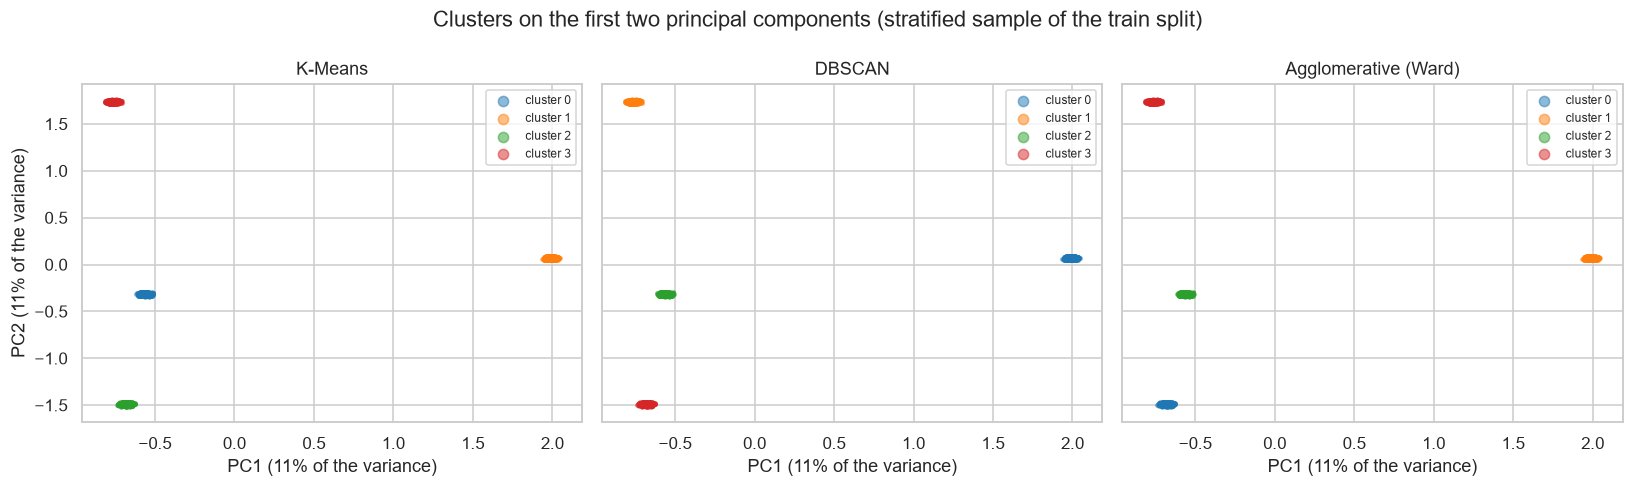

In [13]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(Zs)
P = pca2.transform(Zs_s)
explained2 = [float(v) for v in pca2.explained_variance_ratio_]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, (key, item) in zip(axes, techniques.items()):
    labels = item["labels"]
    palette = sns.color_palette("tab10", n_colors=max(len(set(labels)), 1))
    for index, cluster in enumerate(sorted(set(labels))):
        mask = labels == cluster
        name = "noise" if cluster == -1 else f"cluster {cluster}"
        ax.scatter(P[mask, 0], P[mask, 1], s=5, alpha=0.5, color="#999999" if cluster == -1 else palette[index], label=name)
    ax.set_title(item["label"])
    ax.set_xlabel(f"PC1 ({explained2[0]:.0%} of the variance)")
    ax.legend(markerscale=3, fontsize=8, loc="best")
axes[0].set_ylabel(f"PC2 ({explained2[1]:.0%} of the variance)")
fig.suptitle("Clusters on the first two principal components (stratified sample of the train split)")
fig.tight_layout()
show(fig, "clustering_pca_clusters.png")

## 10. Interpretation

The text below is generated from the numbers above, so it always matches the results of the run.

In [14]:
def spread_text(key):
    sep = risk_separation[key]
    return (f"default rates from {sep['default_rate_min']:.1%} to {sep['default_rate_max']:.1%} "
            f"(spread {sep['spread']:.1%} points; ROC AUC of the cluster rate as a score {sep['cluster_roc_auc']:.3f})")


max_sil = max(m["silhouette"] for m in comparison.values() if m["silhouette"] is not None)
interpretation = [
    f"Structure of the data: the largest correlation between two numeric features is {max_feature_corr:.2f}, so the "
    f"numeric features are almost independent and form one dense cloud.",
    f"The segments that appear are the categories of EmploymentType. With every column standardized, the one-hot "
    f"columns of EmploymentType are the only separated structure: K-Means (k = {best_k}, the highest silhouette, "
    f"{max(s['silhouette'] for s in k_scores):.3f}), DBSCAN (eps = {eps:.2f}, {n_dbscan} clusters, {noise_share:.1%} noise) and "
    f"Agglomerative Clustering (Ward, {best_k} clusters) give the same groups, with an adjusted Rand index with "
    f"EmploymentType of {employment_alignment['kmeans']:.2f}, {employment_alignment['dbscan']:.2f} and "
    f"{employment_alignment['agglomerative']:.2f}, and nearly equal means of every numeric variable in every cluster.",
    f"Without that column, the 8 numeric variables show no groups: the best silhouette of K-Means is "
    f"{numeric_only['best_silhouette']:.3f} (k = {numeric_only['chosen_k']}), against {max_sil:.3f} when the categories are included. "
    f"This is what the near independence of the features predicts: when no variable is related to another, there is no shape for the algorithms to find.",
    f"Do the segments separate the risk? The employment-type segments have {spread_text('kmeans')}, and the numeric-only "
    f"clusters have default rates from {numeric_only['risk_separation']['default_rate_min']:.1%} to "
    f"{numeric_only['risk_separation']['default_rate_max']:.1%}. As a score, the best segmentation reaches a ROC AUC of "
    f"{max(s['cluster_roc_auc'] for s in risk_separation.values()):.3f}, against {model_cv_auc:.3f} of the supervised champion. "
    f"The segments are descriptive: they say who the applicants are and carry a small part of the signal (the default rate of the unemployed segment is the highest), but they do not predict default.",
    f"Effect of the clustering on the data: nothing changes in the data or in the models. The result is consistent with the finding of the dimensionality analysis, where PCA could not compress the features.",
]
for text in interpretation:
    print("-", text, "\n")

- Structure of the data: the largest correlation between two numeric features is 0.00, so the numeric features are almost independent and form one dense cloud. 

- The segments that appear are the categories of EmploymentType. With every column standardized, the one-hot columns of EmploymentType are the only separated structure: K-Means (k = 4, the highest silhouette, 0.237), DBSCAN (eps = 2.44, 4 clusters, 0.0% noise) and Agglomerative Clustering (Ward, 4 clusters) give the same groups, with an adjusted Rand index with EmploymentType of 1.00, 1.00 and 1.00, and nearly equal means of every numeric variable in every cluster. 

- Without that column, the 8 numeric variables show no groups: the best silhouette of K-Means is 0.092 (k = 2), against 0.237 when the categories are included. This is what the near independence of the features predicts: when no variable is related to another, there is no shape for the algorithms to find. 

- Do the segments separate the risk? The employment-type 

### Application to the system (proposal, not implemented)

The segments are **descriptive**, so they should support the analyst and never change the decision or the model in production:

1. **Context in the review screen.** Next to the score, show the segment of the applicant (for example "young, short employment, high debt-to-income ratio") and the real default rate of that segment in the history. The analyst sees how typical or unusual the applicant is.
2. **Unusual applicants.** Applicants that DBSCAN marks as noise, or that are far from every centre, are not represented by the training data; the model score is less reliable for them, so a review with more care can be suggested.
3. **Monitoring.** The share of requests in each segment can be compared month by month together with the PSI of the features: a change in the segment mix is an early sign of drift.
4. **Conditions.** The segmentation would be refitted when the models are retrained, it would be validated with the domain expert, and it would not be used to approve or reject (the age finding of the supervised model shows how a proxy of a sensitive variable can create bias).

Nothing in the application or in the champion changes with this notebook.

## 11. Export

The results are written to `ml/artifacts/clustering_report.json` (validated with `ml.schemas.validate_clustering_report`). The figures were already saved to `static/img/methodology/`.

In [15]:
report = {
    "artifacts_version": manifest["version"],
    "champion": champion,
    "dataset": {"sha256": raw.attrs["sha256"], "train_rows": int(len(X_train))},
    "protocol": {
        "data": "Train split only (80% stratified, seed 42); the test split is deleted right after the split.",
        "random_state": RANDOM_STATE,
        "preprocessing": "Preprocessing of the champion pipeline (12 columns) followed by standardization.",
        "sample_rows": SAMPLE_ROWS,
        "label_usage": "The default label is not an input of any clustering; it is used only to profile the clusters.",
    },
    "independence": {"max_feature_correlation": round(max_feature_corr, 4)},
    "base_default_rate": round(base_rate, 4),
    "model_cv_roc_auc": round(model_cv_auc, 4),
    "kmeans": {
        "k_candidates": [{"k": s["k"], "inertia": round(s["inertia"], 1), "silhouette": round(s["silhouette"], 4)} for s in k_scores],
        "chosen_k": int(best_k),
        "rule": "Highest silhouette on a 10,000-row sample; the elbow of the inertia is shown next to it.",
    },
    "dbscan": {"min_samples": int(MIN_SAMPLES), "eps": round(eps, 4), "n_clusters": n_dbscan, "noise_share": round(noise_share, 4)},
    "agglomerative": {"linkage": "ward", "n_clusters": int(best_k)},
    "comparison": comparison,
    "clusters": clusters,
    "risk_separation": risk_separation,
    "employment_alignment": employment_alignment,
    "numeric_only": numeric_only,
    "interpretation": interpretation,
    "figures": FIGURES,
}
errors = validate_clustering_report(report)
assert not errors, errors
with open(os.path.join(ARTIFACTS_DIR, "clustering_report.json"), "w", encoding="utf-8", newline="\n") as fh:
    json.dump(report, fh, indent=2, ensure_ascii=False)
    fh.write("\n")
print("clustering_report.json written. Figures:", FIGURES)

clustering_report.json written. Figures: ['methodology/clustering_kmeans_selection.png', 'methodology/clustering_dbscan_kdistance.png', 'methodology/clustering_dendrogram.png', 'methodology/clustering_pca_numeric.png', 'methodology/clustering_default_rate.png', 'methodology/clustering_pca_clusters.png']
